# 07 · Own pipeline, part 2: tiling, ensemble, temporal rescoring

The final system, built only from steps that earlier results motivate. Every step is measured on
val, so the table at the end shows what each one adds.

1. **Members.** RT-DETR (best val mAP by far: 0.256, notebook 05), Faster R-CNN (best CNN: 0.209,
   public score 0.230), FCOS-P2 (best recall of the CNNs) and YOLO-P2 (best CNN on small objects,
   notebook 06). Their saved val and test predictions are reused.
2. **Tiled inference + flip TTA** (test-time augmentation). Small objects are the weak point of every
   model, RT-DETR included (AP_small 0.145 vs AP_large 0.44). The detector also runs on overlapping tiles
   of the frame, so small objects are seen at up to 2–3× the resolution. This is the idea of SAHI
   (slicing aided hyper inference; Akyon et al., 2022, Turkey). The settings are searched on every
   10th val frame. FCOS-P2 is not tiled: at 509 ms per pass, several passes per image would not fit the budget.
3. **Ensemble.** The boxes of several models are merged with class-wise NMS (non-maximum suppression):
   where models agree the best box survives, and objects found by only one model are added.
   (WBF, weighted boxes fusion, is a common alternative; it is not used here, as its authors and
   package are Russian.)
4. **Temporal rescoring** (the temporal bonus). Frames are consecutive video: a real object appears in
   neighbouring frames at almost the same place (IoU 0.9, EDA), a false detection usually does not. Each
   box's score is mixed with the score of the best-matching box of the same class in the neighbouring
   frames, the idea of Seq-NMS (Han et al., 2016) in a simplified form.

Runs on Kaggle with two inputs: the output of notebook 05 (it holds the runs of notebooks 02–05,
checkpoints included) and the `yolo_p2` run of notebook 06 uploaded as a dataset.

## Setup

In [2]:
# Setup: clone/update the repo on Colab/Kaggle, install requirements, resolve paths, get the data
import os, sys, subprocess
REPO_URL = "https://github.com/anna-kryvulia/ucu-ai-hw-object-detection.git"
BRANCH = "main"   # branch with the code you pushed
if "google.colab" in sys.modules or os.path.exists("/kaggle/working"):
    ROOT = "/content/repo" if "google.colab" in sys.modules else "/kaggle/working/repo"
    if not os.path.exists(ROOT):
        subprocess.run(["git", "clone", "-q", "-b", BRANCH, REPO_URL, ROOT], check=True)
    else:
        subprocess.run(["git", "-C", ROOT, "pull", "-q"], check=True)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", f"{ROOT}/requirements.txt"], check=True)
    subprocess.run([sys.executable, "-m", "pip", "uninstall", "-y", "-q", "albumentations"],
                   capture_output=True)   # Ultralytics would apply it automatically; not used here
else:
    ROOT = os.path.abspath("..")
sys.path.insert(0, f"{ROOT}/src")

from hwdet import env
from hwdet.data.download import ensure_data
from hwdet.tracker import Run, status
P = env.setup(seed=42)
ensure_data(P, drive_cache=False)   # Colab: the zip goes to the local disk, not Drive
status(P)                           # which runs / stages are already done

restored run yolo_p2 from /kaggle/input/datasets/annakryvulia/yolo-p2-run/runs
restored run fcos_baseline from /kaggle/input/notebooks/annakryvulia/notebook7943026f79/outputs/runs
restored run fcos_center from /kaggle/input/notebooks/annakryvulia/notebook7943026f79/outputs/runs
restored run fcos_ciou from /kaggle/input/notebooks/annakryvulia/notebook7943026f79/outputs/runs
restored run fcos_p2 from /kaggle/input/notebooks/annakryvulia/notebook7943026f79/outputs/runs
restored run frcnn_baseline from /kaggle/input/notebooks/annakryvulia/notebook7943026f79/outputs/runs
restored run frcnn_giou from /kaggle/input/notebooks/annakryvulia/notebook7943026f79/outputs/runs
restored run frcnn_roi_sampling from /kaggle/input/notebooks/annakryvulia/notebook7943026f79/outputs/runs
restored run frcnn_small_anchors from /kaggle/input/notebooks/annakryvulia/notebook7943026f79/outputs/runs
restored run retina_anchors from /kaggle/input/notebooks/annakryvulia/notebook7943026f79/outputs/runs
restored run r

,run_id,stages_done,last_epoch,has_last_ckpt,val_mAP
0,fcos_baseline,"train, eval_val",7,True,0.188795
1,fcos_center,"train, eval_val",7,True,0.174255
2,fcos_ciou,"train, eval_val",7,True,0.190117
3,fcos_p2,"train, eval_val, test",7,True,0.199328
4,frcnn_baseline,"train, eval_val, test",7,True,0.208972
5,frcnn_giou,"train, eval_val",7,True,0.206032
6,frcnn_roi_sampling,"train, eval_val",7,True,0.204962
7,frcnn_small_anchors,"train, eval_val",7,True,0.198372
8,retina_anchors,"train, eval_val",7,True,0.177308
9,retina_baseline,"train, eval_val",7,True,0.186593


In [3]:
# Imports, plot style
import itertools
import json
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import yaml

from hwdet.config import load_config
from hwdet.data.detection_dataset import DetectionDataset, build_targets
from hwdet.data.io import frame_table
from hwdet.engine import inference_speed, load_weights, predict
from hwdet.env import REPO_ROOT
from hwdet.eval.coco_eval import evaluate, evaluate_by_size
from hwdet.models import build_frcnn
from hwdet.pipeline import RUN_FILES, TiledDetector, fetch_kaggle_runs, merge_predictions, temporal_rescore
from hwdet.rtdetr import build_rtdetr
from hwdet.submission import make_submission
from hwdet.viz import INK_3, PALETTE, save_fig, set_style, show_frame
from hwdet.yolo import YoloDetector, predict_kwargs

NOTEBOOK_START = time.time()
set_style()
print("torch", torch.__version__, "| device", env.device())

torch 2.11.0+cu130 | device cuda


## 1. Data

In [4]:
# Frames and targets with the shared protocol: every 10th training frame, full val, every 5th val frame to monitor
protocol = load_config("_protocol")["split"]
train_frames = frame_table(P.data, "train")
train_frames = train_frames[(train_frames.frame - 1) % protocol["train_frame_step"] == 0]
val_frames = frame_table(P.data, "val")
monitor_frames = val_frames[(val_frames.frame - 1) % protocol["monitor_frame_step"] == 0]
test_frames = frame_table(P.data, "test")
targets = build_targets(P.data, pd.concat([train_frames, val_frames]))
pd.DataFrame({"frames": [len(train_frames), len(val_frames), len(monitor_frames), len(test_frames)],
              "frames ≥ 2000 px wide": [(d.width >= 2000).sum() for d in (train_frames, val_frames, monitor_frames, test_frames)]},
             index=["train (subsampled)", "val", "val monitor", "test"])

,frames,frames ≥ 2000 px wide
train (subsampled),2446,404
val,2846,1560
val monitor,571,313
test,3811,0


In [5]:
# Search subsets: every 10th val frame for the tiling settings (GPU), every 5th for ensemble / temporal (CPU)
search_frames = val_frames[(val_frames.frame - 1) % 10 == 0]
print(len(search_frames), "tiling search frames,", (search_frames.width >= 2000).sum(), "of them at least 2000 px wide;",
      len(monitor_frames), "ensemble / temporal search frames")

288 tiling search frames, 157 of them at least 2000 px wide; 571 ensemble / temporal search frames


## 2. Members and their saved predictions

In [6]:
# RT-DETR and Faster R-CNN (with checkpoints), FCOS-P2 (predictions only) from notebook 05's output; YOLO-P2 from notebook 06
KERNEL = "annakryvulia/notebook7943026f79"
fetch_kaggle_runs(P, KERNEL, ["rtdetr_baseline", "frcnn_baseline"])
fetch_kaggle_runs(P, KERNEL, ["fcos_p2"], files=tuple(f for f in RUN_FILES if not f.startswith("checkpoints")))
assert (P.runs / "yolo_p2" / "predictions" / "test.csv").exists(), "yolo_p2 run missing: attach the yolo_p2 dataset"
MEMBERS = ["rtdetr_baseline", "frcnn_baseline", "fcos_p2", "yolo_p2"]
pv = {r: pd.read_csv(P.runs / r / "predictions" / "val.csv") for r in MEMBERS}
pt = {r: pd.read_csv(P.runs / r / "predictions" / "test.csv") for r in MEMBERS}
ms = {r: json.loads((P.runs / r / "metrics.json").read_text())["val"]["ms_per_img"] for r in MEMBERS}


def score(preds, frames=val_frames):
    """Main COCO numbers of a prediction table on a set of labelled frames."""
    m = evaluate(preds[preds.file_name.isin(frames.file_name)], frames, P.data, per_class=False)
    return {k: m[k] for k in ("mAP", "AP50", "AP_small", "AP_medium", "AP_large", "AR_500")}


base = pd.DataFrame({r: {**score(pv[r]), "ms_per_img": ms[r]} for r in MEMBERS}).T
LEAD = base.mAP.idxmax()
print("best single model:", LEAD)
base.round(4)

runs present: rtdetr_baseline, frcnn_baseline
runs present: fcos_p2
best single model: rtdetr_baseline


,mAP,AP50,AP_small,AP_medium,AP_large,AR_500,ms_per_img
rtdetr_baseline,0.2561,0.4956,0.1452,0.2310,0.4395,0.4696,176.3482
frcnn_baseline,0.2090,0.4248,0.0912,0.1829,0.4043,0.4110,140.8473
fcos_p2,0.1993,0.3993,0.0976,0.1844,0.3524,0.4406,509.0468
yolo_p2,0.2010,0.4004,0.1015,0.1900,0.3355,0.3168,148.3332


## 3. Tiled inference and flip TTA

The full frame is always processed (large objects), plus overlapping tiles with 20% overlap. Each tile is
resized by the detector like a whole image, so a 2×2 grid shows objects about 1.7× larger and a 3×3 grid
about 2.5× larger. Tile boxes are moved back to frame coordinates; a box touching an inner tile border is
dropped (that object is cut, and appears whole in a neighbouring tile or the full frame). Flip TTA runs
the window mirrored as well and mirrors the boxes back. All boxes are merged with class-wise NMS at IoU 0.5.

Settings compared on the search subset (every 10th val frame): 2×2 on all frames, 2×2 only on frames at
least 2000 px wide (the low-resolution clips have fewer tiny objects), 3×3 on wide frames, and the full
frame with a flip.

In [7]:
# Detectors rebuilt from their configs + best checkpoints
dev = env.device()
rtdetr = load_weights(build_rtdetr(load_config("rtdetr_baseline")), Run("rtdetr_baseline", None, P), "best", dev)
frcnn = load_weights(build_frcnn(load_config("frcnn_baseline")), Run("frcnn_baseline", None, P), "best", dev)
yolo = YoloDetector(P.runs / "yolo_p2" / "checkpoints" / "best.pt", **predict_kwargs(load_config("yolo_p2")))
DETECTORS = {"rtdetr_baseline": rtdetr, "frcnn_baseline": frcnn, "yolo_p2": yolo}
SETTINGS = {"2x2": {"grid": [2, 2]}, "2x2 wide only": {"grid": [2, 2], "min_width": 2000},
            "3x3 wide only": {"grid": [3, 3], "min_width": 2000}, "full + flip": {"grid": [1, 1], "flip": True}}

run 'rtdetr_baseline' at /kaggle/working/outputs/runs/rtdetr_baseline  done: ['train', 'eval_val', 'test']
run 'frcnn_baseline' at /kaggle/working/outputs/runs/frcnn_baseline  done: ['train', 'eval_val', 'test']
Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings


In [8]:
# Check: every rebuilt detector reproduces its saved predictions on 20 val frames (a loading error shows up here)
check_frames = val_frames.iloc[::143]
check_ds = DetectionDataset(check_frames, P.data, targets)
rows = {}
for name, det in DETECTORS.items():
    p = predict(det, check_ds, dev, batch_size=1, workers=2, desc=f"check {name}")
    rows[name] = {"mAP now": score(p, check_frames)["mAP"], "mAP saved": score(pv[name], check_frames)["mAP"]}
check = pd.DataFrame(rows).T
check["difference"] = check["mAP now"] - check["mAP saved"]
assert (check.difference.abs() < 0.02).all(), "a rebuilt detector does not reproduce its saved predictions"
check.round(4)

,mAP now,mAP saved,difference
rtdetr_baseline,0.2978,0.2978,0.0000
frcnn_baseline,0.2497,0.2485,0.0012
yolo_p2,0.2334,0.2331,0.0003


In [9]:
# Search: every setting x detector on the search subset; rows are saved as they finish (resumable)
search_run = Run("pipe_tiling_search", {"family": "pipeline", "description": "tiling / flip search, every 10th val frame"}, P)
f = search_run.dir / "search.csv"
rows = pd.read_csv(f).to_dict("records") if f.exists() else []
done = {(r["model"], r["setting"]) for r in rows}
search_ds = DetectionDataset(search_frames, P.data, targets)
for name, det in DETECTORS.items():
    if (name, "full") not in done:
        rows.append({"model": name, "setting": "full", **score(pv[name], search_frames), "s_per_img": ms[name] / 1000})
    for s, kw in SETTINGS.items():
        if (name, s) in done:
            continue
        t0 = time.time()
        p = predict(TiledDetector(det, overlap=0.2, **kw), search_ds, dev, batch_size=1, workers=2, desc=f"{name} {s}")
        rows.append({"model": name, "setting": s, **score(p, search_frames), "s_per_img": (time.time() - t0) / len(search_frames)})
        pd.DataFrame(rows).to_csv(f, index=False)
search = pd.DataFrame(rows)
search.to_csv(f, index=False)
print(f"elapsed: {(time.time() - NOTEBOOK_START) / 3600:.2f} h")
search.round(4)

run 'pipe_tiling_search' at /kaggle/working/outputs/runs/pipe_tiling_search  done: nothing yet
elapsed: 0.68 h


,model,setting,mAP,AP50,AP_small,AP_medium,AP_large,AR_500,s_per_img
0,rtdetr_baseline,full,0.2629,0.5055,0.1472,0.2365,0.4574,0.4747,0.1763
1,rtdetr_baseline,2x2,0.2625,0.5118,0.1684,0.2441,0.4735,0.4960,0.8798
2,rtdetr_baseline,2x2 wide only,0.2645,0.5168,0.1484,0.2423,0.4671,0.4789,0.5823
3,rtdetr_baseline,3x3 wide only,0.2605,0.5067,0.1418,0.2353,0.4487,0.4795,1.0214
4,rtdetr_baseline,full + flip,0.2717,0.5249,0.1437,0.2443,0.4651,0.4873,0.3553
5,frcnn_baseline,full,0.2101,0.4243,0.0996,0.1857,0.4071,0.4143,0.1408
6,frcnn_baseline,2x2,0.2050,0.4362,0.1046,0.1897,0.3934,0.4450,0.9360
7,frcnn_baseline,2x2 wide only,0.2019,0.4310,0.0984,0.1820,0.3877,0.4252,0.6117
8,frcnn_baseline,3x3 wide only,0.1963,0.4137,0.0883,0.1780,0.3857,0.4230,1.0863
9,frcnn_baseline,full + flip,0.2159,0.4352,0.1016,0.1898,0.4162,0.4311,0.3932


In [10]:
# Best setting per detector by search mAP, among settings whose full val + test run fits its time budget
BUDGET_H = {"rtdetr_baseline": 1.0, "frcnn_baseline": 0.6, "yolo_p2": 0.4}
n_full = len(val_frames) + len(test_frames)
search["hours_full_run"] = search.s_per_img * n_full / 3600
chosen = {}
for name in DETECTORS:
    s = search[(search.model == name) & (search.hours_full_run <= BUDGET_H[name])]
    chosen[name] = s.loc[s.mAP.idxmax(), "setting"]
print("chosen:", chosen)
search.pivot(index="setting", columns="model", values=["mAP", "AP_small", "hours_full_run"]).round(3)

chosen: {'rtdetr_baseline': 'full + flip', 'frcnn_baseline': 'full', 'yolo_p2': 'full'}


mAP                               AP_small  \
model         frcnn_baseline rtdetr_baseline yolo_p2 frcnn_baseline   
setting                                                               
2x2                    0.205           0.263   0.210          0.105   
2x2 wide only          0.202           0.264   0.204          0.098   
3x3 wide only          0.196           0.261   0.198          0.088   
full                   0.210           0.263   0.202          0.100   
full + flip            0.216           0.272   0.210          0.102   

                                      hours_full_run                          
model         rtdetr_baseline yolo_p2 frcnn_baseline rtdetr_baseline yolo_p2  
setting                                                                       
2x2                     0.168   0.122          1.731           1.627   1.345  
2x2 wide only           0.148   0.104          1.131           1.077   0.969  
3x3 wide only           0.142   0.099          2.009           1.889   1.234  
full                    0.147   0.105          0.260           0.326   0.274  
full + flip             0.144   0.113          0.727           0.657   0.667

In [11]:
# Chosen setting on the full val split (metrics + speed) and on test; each tiled model is a run of its own
tiled_v, tiled_t = {"fcos_p2": pv["fcos_p2"]}, {"fcos_p2": pt["fcos_p2"]}
for name, setting in chosen.items():
    if setting == "full":
        tiled_v[name], tiled_t[name] = pv[name], pt[name]
        continue
    rid = f"pipe_{name.split('_')[0]}_tiled"
    run = Run(rid, {"family": "pipeline", "model": {"arch": name}, "tiling": {"setting": setting, **SETTINGS[setting]},
                    "description": f"{name} with tiled inference: {setting}, overlap 0.2, NMS 0.5"}, P)
    det = TiledDetector(DETECTORS[name], overlap=0.2, **SETTINGS[setting])
    if not run.is_done("eval_val"):
        val_ds = DetectionDataset(val_frames, P.data, targets)
        p = predict(det, val_ds, dev, batch_size=1, workers=2, desc=f"{rid} val")
        p.to_csv(run.pred_path("val"), index=False)
        m = evaluate(p, val_frames, P.data)
        m.update(inference_speed(det, val_ds, dev, n=20))
        run.log_metrics("val", m)
        run.mark_done("eval_val")
    if not run.is_done("test"):
        p = predict(det, DetectionDataset(test_frames, P.data), dev, batch_size=1, workers=2, desc=f"{rid} test")
        p.to_csv(run.pred_path("test"), index=False)
        make_submission(p, test_frames, run.dir / "submission.csv")
        run.mark_done("test")
    tiled_v[name], tiled_t[name] = pd.read_csv(run.pred_path("val")), pd.read_csv(run.pred_path("test"))
    ms[name] = run.metrics["val"]["ms_per_img"]
print(f"elapsed: {(time.time() - NOTEBOOK_START) / 3600:.2f} h")
pd.DataFrame({n: {**score(tiled_v[n]), "ms_per_img": ms[n]} for n in MEMBERS}).T.round(4)

run 'pipe_rtdetr_tiled' at /kaggle/working/outputs/runs/pipe_rtdetr_tiled  done: nothing yet
submission looks valid
wrote /kaggle/working/outputs/runs/pipe_rtdetr_tiled/submission.csv (3811 rows, 923842 boxes)
elapsed: 1.33 h


,mAP,AP50,AP_small,AP_medium,AP_large,AR_500,ms_per_img
rtdetr_baseline,0.2659,0.5160,0.1453,0.2396,0.4496,0.4805,331.1244
frcnn_baseline,0.2090,0.4248,0.0912,0.1829,0.4043,0.4110,140.8473
fcos_p2,0.1993,0.3993,0.0976,0.1844,0.3524,0.4406,509.0468
yolo_p2,0.2010,0.4004,0.1015,0.1900,0.3355,0.3168,148.3332


## 4. Ensemble

The best single model plus every combination of the others, merged with class-wise NMS at IoU 0.5 or 0.6
(a higher IoU keeps more neighbouring boxes, which matters in crowded scenes). The models' scores are not
calibrated to each other, so the other members' scores are also tried at half weight: their boxes then
fill gaps instead of outranking the strongest model. Searched on the val monitor subset (every 5th frame).

In [12]:
# Ensemble search on every 5th val frame
label = {n: f"{n} ({chosen.get(n, 'full')})" for n in MEMBERS}
others = [m for m in MEMBERS if m != LEAD]
rows = [{"members": label[LEAD], "combo": (LEAD,), "nms_iou": None, "weight_others": None, **score(tiled_v[LEAD], monitor_frames)}]
for k in (1, 2, 3):
    for extra in itertools.combinations(others, k):
        combo = (LEAD,) + extra
        for iou in (0.5, 0.6):
            for w in (1.0, 0.5):
                p = merge_predictions([tiled_v[c] for c in combo], iou=iou, weights=[1.0] + [w] * k)
                rows.append({"members": " + ".join(label[c] for c in combo), "combo": combo, "nms_iou": iou,
                             "weight_others": w, **score(p, monitor_frames)})
ens = pd.DataFrame(rows).sort_values("mAP", ascending=False).reset_index(drop=True)
ens.drop(columns="combo").round(4)

,members,nms_iou,weight_others,mAP,AP50,AP_small,AP_medium,AP_large,AR_500
0,rtdetr_baseline (full + flip) + yolo_p2 (full),0.6,1.0,0.2726,0.5249,0.1451,0.2458,0.4494,0.5013
1,rtdetr_baseline (full + flip) + yolo_p2 (full),0.5,1.0,0.2722,0.5248,0.1447,0.2455,0.4484,0.4973
2,rtdetr_baseline (full + flip) + frcnn_baseline...,0.6,0.5,0.2718,0.5269,0.1450,0.2454,0.4667,0.5090
3,rtdetr_baseline (full + flip) + yolo_p2 (full),0.6,0.5,0.2711,0.5253,0.1449,0.2446,0.4616,0.5022
4,rtdetr_baseline (full + flip) + frcnn_baseline...,0.5,0.5,0.2710,0.5262,0.1446,0.2450,0.4622,0.5042
5,rtdetr_baseline (full + flip) + frcnn_baseline...,0.6,0.5,0.2708,0.5249,0.1449,0.2441,0.4650,0.5091
6,rtdetr_baseline (full + flip) + frcnn_baseline...,0.6,0.5,0.2708,0.5250,0.1444,0.2444,0.4654,0.5019
7,rtdetr_baseline (full + flip) + yolo_p2 (full),0.5,0.5,0.2707,0.5250,0.1445,0.2442,0.4605,0.4983
8,rtdetr_baseline (full + flip) + fcos_p2 (full)...,0.6,0.5,0.2705,0.5243,0.1449,0.2438,0.4626,0.5082
9,rtdetr_baseline (full + flip) + frcnn_baseline...,0.6,0.5,0.2704,0.5241,0.1447,0.2437,0.4636,0.5068


In [13]:
# Best ensemble on the full val split and on test, logged as its own run for the summary table
best = ens.iloc[0]
if len(best.combo) == 1:
    ens_v, ens_t = tiled_v[LEAD], tiled_t[LEAD]
else:
    weights = [1.0] + [best.weight_others] * (len(best.combo) - 1)
    ens_v = merge_predictions([tiled_v[c] for c in best.combo], iou=best.nms_iou, weights=weights)
    ens_t = merge_predictions([tiled_t[c] for c in best.combo], iou=best.nms_iou, weights=weights)
ens_run = Run("pipe_ensemble", {"family": "pipeline", "model": {"arch": "ensemble"},
                                "description": f"NMS ensemble of {best.members}, IoU {best.nms_iou}, "
                                               f"weight of the others {best.weight_others}"}, P)
ens_run.log_metrics("val", {**evaluate(ens_v, val_frames, P.data), "ms_per_img": sum(ms[c] for c in best.combo)})
pd.Series(ens_run.metrics["val"]).round(4)

run 'pipe_ensemble' at /kaggle/working/outputs/runs/pipe_ensemble  done: nothing yet


mAP              0.2702
AP50             0.5217
AP75             0.2463
AP_small         0.1381
AP_medium        0.2437
AP_large         0.4406
AR_10            0.3757
AR_100           0.4924
AR_500           0.4961
AR_small         0.2940
AR_medium        0.4792
AR_large         0.6367
AP_person        0.3086
AP_bicycle       0.2572
AP_car           0.4339
AP_van           0.3117
AP_truck         0.2684
AP_tricycle      0.2628
AP_bus           0.1833
AP_motor         0.1354
ms_per_img     479.4577
dtype: float64

## 5. Temporal rescoring

For each box: the best IoU match of the same class in each of the `window` previous and next frames
(IoU ≥ 0.5, else 0). New score = (1 − λ) · own score + λ · mean neighbour score. With λ = 0 nothing changes.
Only the ranking of the boxes changes, which is what AP measures: persistent objects move up, one-frame
flickers move down. The video clips of val and test are complete, so every frame has its neighbours.
Rescoring uses all val frames; the settings are compared on every 5th frame.

In [14]:
# Search window x lambda (rescoring on all val frames, scores on every 5th)
rows = [{"window": 0, "lam": 0.0, **score(ens_v, monitor_frames)}]
for window in (1, 2):
    for lam in (0.25, 0.5, 0.75):
        p = temporal_rescore(ens_v, val_frames, window=window, iou_thr=0.5, lam=lam)
        rows.append({"window": window, "lam": lam, **score(p, monitor_frames)})
temporal = pd.DataFrame(rows).sort_values("mAP", ascending=False).reset_index(drop=True)
temporal.round(4)

,window,lam,mAP,AP50,AP_small,AP_medium,AP_large,AR_500
0,2,0.25,0.2760,0.5284,0.1434,0.2491,0.4561,0.5013
1,1,0.25,0.2757,0.5288,0.1442,0.2478,0.4543,0.5013
2,1,0.50,0.2743,0.5239,0.1418,0.2470,0.4561,0.5013
3,2,0.50,0.2737,0.5214,0.1414,0.2479,0.4597,0.5013
4,0,0.00,0.2726,0.5249,0.1451,0.2458,0.4494,0.5013
5,1,0.75,0.2701,0.5135,0.1440,0.2428,0.4538,0.5013
6,2,0.75,0.2673,0.5061,0.1432,0.2432,0.4555,0.5013


## 6. Final pipeline and submission

In [15]:
# Final pipeline = best ensemble + best temporal setting; val metrics, test submission
w, lam = int(temporal.window[0]), float(temporal.lam[0])
final_v = temporal_rescore(ens_v, val_frames, w, 0.5, lam) if w else ens_v
final_t = temporal_rescore(ens_t, test_frames, w, 0.5, lam) if w else ens_t
final = Run("pipe_final", {"family": "pipeline", "model": {"arch": "ensemble + temporal"},
                           "description": f"{best.members}, NMS IoU {best.nms_iou}, weight of the others "
                                          f"{best.weight_others}, temporal window {w}, lambda {lam}"}, P)
final_v.to_csv(final.pred_path("val"), index=False)
final_t.to_csv(final.pred_path("test"), index=False)
final.log_metrics("val", {**evaluate(final_v, val_frames, P.data), "ms_per_img": sum(ms[c] for c in best.combo)})
make_submission(final_t, test_frames, final.dir / "submission.csv")
pd.Series(final.metrics["val"]).round(4)

run 'pipe_final' at /kaggle/working/outputs/runs/pipe_final  done: nothing yet
submission looks valid
wrote /kaggle/working/outputs/runs/pipe_final/submission.csv (3811 rows, 1552464 boxes)


mAP              0.2728
AP50             0.5244
AP75             0.2491
AP_small         0.1377
AP_medium        0.2476
AP_large         0.4485
AR_10            0.3765
AR_100           0.4928
AR_500           0.4961
AR_small         0.2940
AR_medium        0.4792
AR_large         0.6367
AP_person        0.3066
AP_bicycle       0.2568
AP_car           0.4316
AP_van           0.3153
AP_truck         0.2700
AP_tricycle      0.2700
AP_bus           0.1922
AP_motor         0.1401
ms_per_img     479.4577
dtype: float64

## 7. What each step adds

From the best single model to the final pipeline, all on the full val split. The settings were chosen on
subsets of val, so the last rows are slightly optimistic; the public leaderboard score of the submission
is the independent check.

In [16]:
# Ablation: best single model -> + tiling -> + ensemble -> + temporal
steps = {f"{LEAD} (single model)": pv[LEAD], f"+ tiling ({chosen.get(LEAD, 'full')})": tiled_v[LEAD],
         f"+ ensemble ({best.members})": ens_v, f"+ temporal (window {w}, λ {lam})": final_v}
ablation = pd.DataFrame({k: score(v) for k, v in steps.items()}).T
ablation.round(4)

,mAP,AP50,AP_small,AP_medium,AP_large,AR_500
rtdetr_baseline (single model),0.2561,0.4956,0.1452,0.2310,0.4395,0.4696
+ tiling (full + flip),0.2659,0.5160,0.1453,0.2396,0.4496,0.4805
+ ensemble (rtdetr_baseline (full + flip) + yolo_p2 (full)),0.2702,0.5217,0.1381,0.2437,0.4406,0.4961
"+ temporal (window 2, λ 0.25)",0.2728,0.5244,0.1377,0.2476,0.4485,0.4961


In [17]:
# AP by object size (sides in original pixels): best single model vs final pipeline
pd.concat({"single model": evaluate_by_size(pv[LEAD], val_frames, P.data),
           "final pipeline": evaluate_by_size(final_v, val_frames, P.data)}, names=["model", "object side"]).round(4)

objects      AP    AP50  AR_500
model          object side                                 
single model   < 16 px          380  0.0048  0.0185  0.0649
               16–32 px       21530  0.1464  0.4354  0.2822
               32–96 px       79357  0.2310  0.4744  0.4560
               > 96 px        12865  0.4395  0.7092  0.6118
final pipeline < 16 px          380  0.0095  0.0288  0.0645
               16–32 px       21530  0.1391  0.4012  0.2955
               32–96 px       79357  0.2476  0.5042  0.4792
               > 96 px        12865  0.4485  0.7357  0.6367

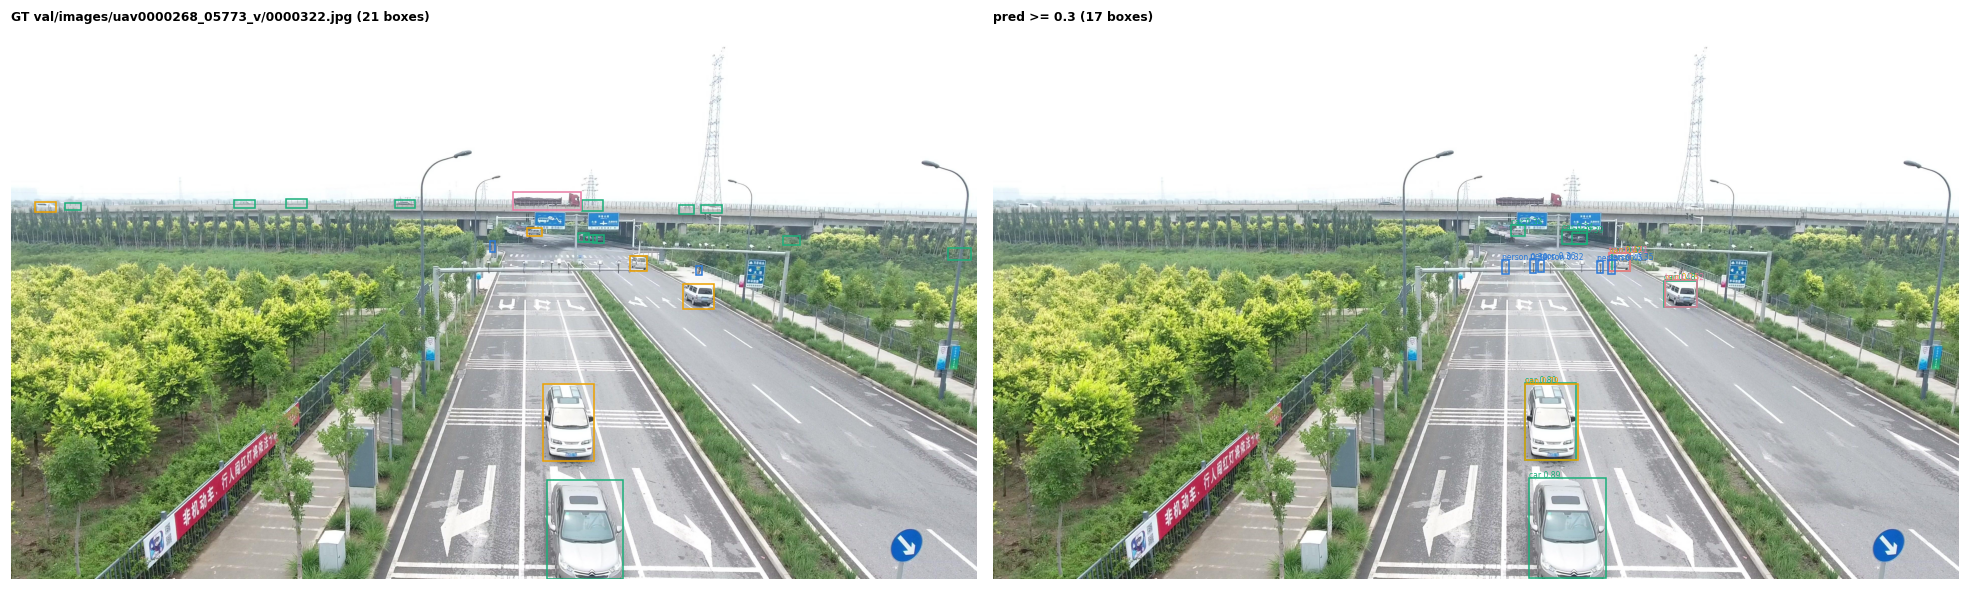

In [18]:
# A crowded 4K val frame: ground truth (left) and final pipeline boxes with score >= 0.3 (right)
n_obj = val_frames.file_name.map(lambda fn: len(targets[fn]["boxes"]))
wide = val_frames[val_frames.width >= 3000]
row = wide.loc[n_obj[wide.index].idxmax()]
fig = show_frame(P.data, row, final_v, score_thr=0.3, figsize=(18, 6))
save_fig(fig, "pipeline_example", P)
plt.show()

## 8. Summary of all models

In [19]:
# Every model of the homework on the full val split: earlier rows from results/experiments.csv, new runs from disk
rows = {}
old = pd.read_csv(REPO_ROOT / "results" / "experiments.csv")
for r in old[old["eval"] == "val"].to_dict("records"):
    rows[r["run_id"]] = r
for d in sorted(P.runs.iterdir()):
    if (d / "metrics.json").exists() and "val" in json.loads((d / "metrics.json").read_text()):
        c = yaml.safe_load((d / "config.yaml").read_text()) if (d / "config.yaml").exists() else None
        c = c or {}
        rows[d.name] = {"run_id": d.name, "family": c.get("family", ""), **json.loads((d / "metrics.json").read_text())["val"]}
summary = pd.DataFrame(rows.values()).set_index("run_id")
summary = summary[["family", "mAP", "AP50", "AP_small", "AP_medium", "AP_large", "AR_500", "ms_per_img"]]
summary = summary.sort_values("mAP", ascending=False)
summary.round(3)

,family,mAP,AP50,AP_small,AP_medium,AP_large,AR_500,ms_per_img
run_id,,,,,,,,
pipe_final,pipeline,0.273,0.524,0.138,0.248,0.448,0.496,479.458
pipe_ensemble,pipeline,0.270,0.522,0.138,0.244,0.441,0.496,479.458
pipe_rtdetr_tiled,pipeline,0.266,0.516,0.145,0.240,0.450,0.481,331.124
rtdetr_denoise,query_based,0.256,0.493,0.136,0.233,0.439,0.464,176.439
rtdetr_baseline,query_based,0.256,0.496,0.145,0.231,0.439,0.470,176.348
rtdetr_queries,query_based,0.254,0.494,0.144,0.237,0.422,0.470,178.244
rtdetr_matching,query_based,0.249,0.481,0.144,0.226,0.422,0.423,176.534
frcnn_baseline,two_stage,0.209,0.425,0.091,0.183,0.404,0.411,140.847
frcnn_giou,two_stage,0.206,0.431,0.099,0.193,0.368,0.398,140.446


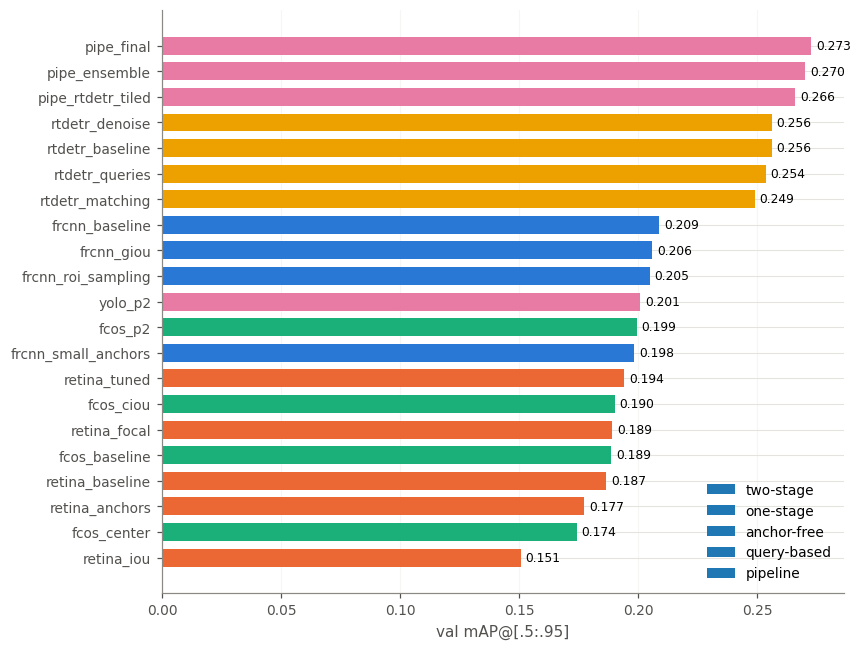

In [20]:
# Bar chart of val mAP for all models, coloured by family
families = ["two_stage", "one_stage", "anchor_free", "query_based", "pipeline"]
s = summary.sort_values("mAP")
fig, ax = plt.subplots(figsize=(8, 0.28 * len(s) + 1))
ax.barh(s.index, s.mAP, color=[PALETTE[families.index(f)] if f in families else INK_3 for f in s.family], height=0.7)
for fam in families:
    if fam in set(s.family):
        ax.barh([], [], color=PALETTE[families.index(fam)], label=fam.replace("_", "-"))
for y, v in enumerate(s.mAP):
    ax.text(v + 0.002, y, f"{v:.3f}", va="center", fontsize=8)
ax.set_xlabel("val mAP@[.5:.95]")
ax.legend(loc="lower right")
ax.grid(axis="x", alpha=0.3)
save_fig(fig, "pipeline_summary", P)
plt.show()

In [21]:
# Distinct warnings logged in this session (should be empty), total time
print(f"total: {(time.time() - NOTEBOOK_START) / 3600:.2f} h")
env.warnings_summary(P)

total: 1.51 h


[]